# Projet Leyenda - Livrable 2
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [ ]:
%pip requirements.txt

In [ ]:
import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.preprocessing.text import tokenizer_from_json
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
from tensorflow.keras.preprocessing.text import text_to_word_sequence
import shutil
from pycocoevalcap.cider.cider import Cider



## Etape 1 : Chargement des données



In [ ]:
DATA_DIR = Path("data")
SRC_JSON = DATA_DIR / "annotations" / "captions_train2014.json"
TRAIN_DIR = DATA_DIR / "train2014"
VAL_DIR = DATA_DIR / "val2014"

TRAIN_SPLIT_JSON = DATA_DIR / "annotations" / "captions_train_split.json"
VAL_SPLIT_JSON = DATA_DIR / "annotations" / "captions_val_split.json"

VAL_RATIO = 0.2
SEED = 42


def create_train_val_split():
    if TRAIN_SPLIT_JSON.exists() and VAL_SPLIT_JSON.exists():
        print("Split déjà créé, rien à faire.")
        return

    with SRC_JSON.open("r", encoding="utf-8") as f:
        data = json.load(f)

    images = [img for img in data["images"] if (TRAIN_DIR / img["file_name"]).is_file()]
    print(f"Images disponibles dans train2014 : {len(images):,}")

    rng = np.random.default_rng(SEED)
    order = rng.permutation(len(images))
    n_val = int(len(images) * VAL_RATIO)

    val_ids = {images[i]["id"] for i in order[:n_val]}
    train_ids = {img["id"] for img in images} - val_ids

    def subset(keep_ids):
        return {
            "info": data.get("info", {}),
            "licenses": data.get("licenses", []),
            "images": [img for img in images if img["id"] in keep_ids],
            "annotations": [a for a in data["annotations"] if a["image_id"] in keep_ids],
        }

    VAL_DIR.mkdir(parents=True, exist_ok=True)
    copied = 0
    for img in images:
        if img["id"] in val_ids:
            dst = VAL_DIR / img["file_name"]
            if not dst.exists():
                shutil.copy2(TRAIN_DIR / img["file_name"], dst)
                copied += 1

    with TRAIN_SPLIT_JSON.open("w", encoding="utf-8") as f:
        json.dump(subset(train_ids), f)
    with VAL_SPLIT_JSON.open("w", encoding="utf-8") as f:
        json.dump(subset(val_ids), f)

    print(f"train : {len(train_ids):,} images | validation : {len(val_ids):,} images")
    print(f"Images copiées : {copied:,} | total dans val2014 : {len(list(VAL_DIR.glob('*.jpg'))):,}")


create_train_val_split()


Split déjà créé, rien à faire.


In [ ]:
ANNOTATION_FILES = {
    "train": DATA_DIR / "annotations" / "captions_train_split.json",
    "validation": DATA_DIR / "annotations" / "captions_val_split.json",
}
IMAGE_DIRS = {
    "train": DATA_DIR / "train2014",
    "validation": DATA_DIR / "val2014",
}

def load_split(split):
    with ANNOTATION_FILES[split].open("r", encoding="utf-8") as f:
        data = json.load(f)

    records = {}
    for image in data["images"]:
        image_id = image["id"]
        if image_id in records:
            raise ValueError(f"{split} : ID image dupliqué {image_id}")
        records[image_id] = {
            "image_id": image_id,
            "image_path": IMAGE_DIRS[split] / image["file_name"],
            "captions": [],
        }

    for ann in data["annotations"]:
        image_id = ann["image_id"]
        if image_id not in records:
            raise ValueError(f"{split} : légende liée à une image inconnue {image_id}")
        records[image_id]["captions"].append(ann["caption"])

    missing_files = [r["image_path"] for r in records.values() if not r["image_path"].is_file()]
    no_caption = [i for i, r in records.items() if not r["captions"]]
    n_captions = sum(len(r["captions"]) for r in records.values())

    print(f"{split} : {len(records):,} images, {n_captions:,} légendes")
    print(f"  images introuvables sur disque : {len(missing_files)}")
    print(f"  images sans légende            : {len(no_caption)}")
    if missing_files:
        print("  exemples manquants :", missing_files[:3])

    return records

train_records = load_split("train")
val_records = load_split("validation")

shared = set(train_records) & set(val_records)
print("IDs communs train/validation :", len(shared))


train : 66,227 images, 331,304 légendes
  images introuvables sur disque : 0
  images sans légende            : 0
validation : 16,556 images, 82,809 légendes
  images introuvables sur disque : 0
  images sans légende            : 0
IDs communs train/validation : 0


In [33]:
example = next(iter(train_records.values()))

print("ID image :", example["image_id"])
print("Chemin :", example["image_path"])

for caption in example["captions"]:
    print("-", caption)

ID image : 57870
Chemin : Data\train2014\COCO_train2014_000000057870.jpg
- A restaurant has modern wooden tables and chairs.
- A long restaurant table with rattan rounded back chairs.
- a long table with a plant on top of it surrounded with wooden chairs 
- A long table with a flower arrangement in the middle for meetings
- A table is adorned with wooden chairs with blue accents.


# Etape 2 : Prétraitement des données

In [ ]:
IMAGE_SIZE = (299, 299)
BATCH_SIZE = 32

inception = InceptionV3(
    weights="imagenet",
    include_top=False,
    pooling=None,
    input_shape=(*IMAGE_SIZE, 3),
)

inception.trainable = False

inputs = Input(
    shape=(*IMAGE_SIZE, 3),
    name="image_input",)

outputs = inception(inputs, training=False)

image_encoder = Model(
    inputs=inputs,
    outputs=outputs,
    name="image_encoder",
)

print("Entrée :", image_encoder.input_shape)
print("Sortie :", image_encoder.output_shape)

Entrée : (None, 299, 299, 3)
Sortie : (None, 8, 8, 2048)


Charger et preprocess 

In [ ]:
def load_and_preprocess_image(image_id, image_path):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(
        image_bytes,
        channels=3,
    )

    image = tf.image.resize(image, IMAGE_SIZE)
    image = preprocess_input(image)

    return image_id, image

Créer le dataset avec le lien image id et image path

In [ ]:
def make_image_dataset(records):
    image_ids = np.array(list(records.keys()), dtype=np.int64)

    image_paths = [
        str(records[int(image_id)]["image_path"])
        for image_id in image_ids]

    dataset = tf.data.Dataset.from_tensor_slices((image_ids, image_paths))
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_image_dataset = make_image_dataset(train_records)
val_image_dataset = make_image_dataset(val_records)

print("Datasets train et validation créés.")

Datasets train et validation créés.


Test avec un batch

In [ ]:
batch_ids, batch_images = next(iter(train_image_dataset))
batch_features = image_encoder(batch_images, training=False)
batch_features = tf.reshape(
    batch_features,
    (tf.shape(batch_features)[0], 64, 2048),
)

print("Caractéristiques :", batch_features.shape)


Caractéristiques : (32, 64, 2048)


## Extraction des features

In [ ]:
FEATURES_DIR = Path("features/inception_grid_fp16")

N_TRAIN_IMAGES = 50_000
N_VAL_IMAGES = 12_000
SEED = 42


def extract_features(records, split_name, n_images=None):
    out_dir = FEATURES_DIR / split_name
    out_dir.mkdir(parents=True, exist_ok=True)
   
    if n_images is not None:
        all_ids = np.array(sorted(records), dtype=np.int64)
        rng = np.random.default_rng(SEED)
        selected = rng.choice(all_ids, size=min(n_images, len(all_ids)), replace=False)
        records = {int(i): records[int(i)] for i in selected}

    pending = [i for i in records if not (out_dir / f"{i}.npy").exists()]
    already_done = len(records) - len(pending)

    print(f"{split_name} : {len(records):,} images retenues, "
          f"{already_done:,} déjà faites, {len(pending):,} à traiter")
    if not pending:
        return

    dataset = make_image_dataset({i: records[i] for i in pending})
    total_batches = (len(pending) + BATCH_SIZE - 1) // BATCH_SIZE

    start = time.time()
    done = 0

    for batch_number, (image_ids, images) in enumerate(dataset, start=1):
        features = image_encoder(images, training=False)                      
        features = tf.reshape(features, (tf.shape(features)[0], 64, 2048))   
        features = features.numpy().astype(np.float16)

        for image_id, vector in zip(image_ids.numpy(), features):
            tmp_path = out_dir / f"{image_id}.tmp.npy"
            np.save(tmp_path, vector)
            tmp_path.replace(out_dir / f"{image_id}.npy")

        done += len(features)

        if batch_number % 100 == 0 or batch_number == total_batches:
            speed = done / (time.time() - start)
            print(f"{split_name} : {batch_number}/{total_batches} batches, {speed:.1f} images/s", flush=True)

In [39]:
extract_features(train_records, "train", n_images=N_TRAIN_IMAGES)
extract_features(val_records, "validation", n_images=N_VAL_IMAGES)

train : 30,000 images retenues, 30,000 déjà faites, 0 à traiter
validation : 10,000 images retenues, 10,000 déjà faites, 0 à traiter


In [ ]:
for split, records in [("train", train_records), ("validation", val_records)]:
    out_dir = FEATURES_DIR / split
    files = [p for p in out_dir.glob("*.npy") if not p.name.endswith(".tmp.npy")]
    print(f"{split} : {len(files):,} fichiers pour {len(records):,} images")

example = np.load(files[0])
print("Forme :", example.shape, "| type :", example.dtype)  

train : 30,000 fichiers pour 66,227 images
validation : 10,000 fichiers pour 16,556 images
Forme : (64, 2048) | type : float16


Prépare caption

In [41]:
def prepare_captions(records):
    image_ids = []
    captions = []

    for image_id, record in records.items():
        for caption in record["captions"]:
            image_ids.append(image_id)
            captions.append(f"startseq {caption.strip()} endseq")

    return np.asarray(image_ids, dtype=np.int64), captions


train_caption_image_ids, train_captions = prepare_captions(train_records)
val_caption_image_ids, val_captions = prepare_captions(val_records)

print("Légendes train :", len(train_captions))
print("Légendes validation :", len(val_captions))

Légendes train : 331304
Légendes validation : 82809


Tokenizer

In [42]:
TOP_K = 7000

tokenizer = Tokenizer(num_words=TOP_K, oov_token="unk")
tokenizer.fit_on_texts(train_captions)   

train_sequences = tokenizer.texts_to_sequences(train_captions)
val_sequences = tokenizer.texts_to_sequences(val_captions)

vocab_size = min(TOP_K, len(tokenizer.word_index))

start_token_id = tokenizer.word_index["startseq"]
end_token_id = tokenizer.word_index["endseq"]

assert start_token_id < vocab_size
assert end_token_id < vocab_size

print("vocab_size :", vocab_size)
print("startseq :", start_token_id, "| endseq :", end_token_id)

vocab_size : 7000
startseq : 3 | endseq : 4


In [43]:
max_length = 20

def truncate_keep_end(sequences):
    return [
        seq if len(seq) <= max_length
        else seq[:max_length - 1] + [end_token_id]
        for seq in sequences
    ]

train_sequences = truncate_keep_end(train_sequences)
val_sequences = truncate_keep_end(val_sequences)

train_caption_tokens = pad_sequences(
    train_sequences, maxlen=max_length,
    padding="post", truncating="post", value=0, dtype="int32",
)

val_caption_tokens = pad_sequences(
    val_sequences, maxlen=max_length,
    padding="post", truncating="post", value=0, dtype="int32",
)


print("Longueur maximale :", max_length)
print("Train :", train_caption_tokens.shape)
print("Validation :", val_caption_tokens.shape)

Longueur maximale : 20
Train : (331304, 20)
Validation : (82809, 20)


In [44]:
print("vocab_size :", vocab_size)
print("max_length :", max_length)
print("indice max dans train :", train_caption_tokens.max())
print("indice max dans validation :", val_caption_tokens.max())
print("unk :", tokenizer.word_index["unk"],
      "| startseq :", start_token_id,
      "| endseq :", end_token_id)

assert train_caption_tokens.max() < vocab_size
assert val_caption_tokens.max() < vocab_size

vocab_size : 7000
max_length : 20
indice max dans train : 6999
indice max dans validation : 6999
unk : 1 | startseq : 3 | endseq : 4


Encodeur CNN

In [45]:
EMBEDDING_DIM = 256   


class CNN_Encoder(tf.keras.Model):
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = tf.keras.layers.Dense(embedding_dim)

    def call(self, x):
        x = self.fc(x)        
        x = tf.nn.relu(x)
        return x


encoder = CNN_Encoder(EMBEDDING_DIM)

## Mécanisme d’attention de Bahdanau

In [46]:
class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units):
        super().__init__()

        self.W1 = tf.keras.layers.Dense(units)
        self.W2 = tf.keras.layers.Dense(units)
        self.V = tf.keras.layers.Dense(1)

    def call(self, features, hidden):
        

        hidden_with_time_axis = tf.expand_dims(hidden, axis=1)

        
        attention_hidden = tf.nn.tanh(
            self.W1(features) + self.W2(hidden_with_time_axis)
        )

        
        scores = self.V(attention_hidden)

        
        attention_weights = tf.nn.softmax(scores, axis=1)

        
        context_vector = tf.reduce_sum(
            attention_weights * features,
            axis=1,
        )

        return context_vector, attention_weights

In [47]:
RNN_UNITS = 512
ATTENTION_UNITS = 512


attention_test = BahdanauAttention(ATTENTION_UNITS)

encoded_features = encoder(batch_features)


hidden_test = tf.zeros(
    (tf.shape(encoded_features)[0], RNN_UNITS),
    dtype=encoded_features.dtype,
)

context_vector, attention_weights = attention_test(
    encoded_features,
    hidden_test,
)

print("Caractéristiques encodées :", encoded_features.shape)
print("État caché :", hidden_test.shape)
print("Vecteur de contexte :", context_vector.shape)
print("Poids d’attention :", attention_weights.shape)

tf.debugging.assert_near(
    tf.reduce_sum(attention_weights, axis=1),
    tf.ones_like(attention_weights[:, 0, :]),
    atol=1e-5,
)

tf.debugging.assert_all_finite(
    context_vector,
    "Le vecteur de contexte contient des valeurs invalides.",
)

Caractéristiques encodées : (32, 64, 256)
État caché : (32, 512)
Vecteur de contexte : (32, 256)
Poids d’attention : (32, 64, 1)


<tf.Tensor: shape=(32, 256), dtype=float32, numpy=
array([[0.02259057, 0.3018156 , 0.04447925, ..., 0.23813464, 0.32865256,
        0.14197782],
       [0.15118535, 0.61051357, 0.13996838, ..., 0.01005496, 0.10138236,
        0.12020264],
       [0.01456543, 0.8210311 , 0.01971657, ..., 0.00343761, 0.19305792,
        0.44960546],
       ...,
       [0.06618585, 0.93356824, 0.04410011, ..., 0.00819393, 0.14781296,
        0.51895773],
       [0.40417898, 1.3557324 , 0.06120327, ..., 0.27659202, 0.07948859,
        0.81093746],
       [0.03498773, 0.6723468 , 0.04706844, ..., 0.0063416 , 0.05659203,
        0.03279601]], shape=(32, 256), dtype=float32)>

## Décodeur RNN

In [ ]:
class RNN_Decoder(tf.keras.Model):
    def __init__(self, embedding_dim, units, vocab_size,
                 attention_units=512, dropout_rate=0.3, gru_dropout=0.0):
        super().__init__()
        self.units = units
        self.embedding = layers.Embedding(vocab_size, embedding_dim)
        self.attention = BahdanauAttention(attention_units)
        self.gru = layers.GRU(units,
                              return_sequences=True,
                              return_state=True)
        self.fc1 = layers.Dense(units)
        self.fc2 = layers.Dense(vocab_size)

    def call(self, word_id, features, hidden, training=False):
        context_vector, attention_weights = self.attention(features, hidden)

        x = self.embedding(word_id)
        context = tf.expand_dims(context_vector, axis=1)
        x = tf.concat([context, x], axis=-1)

        output, hidden = self.gru(x, initial_state=hidden, training=training)

        x = self.fc1(output)
        x = tf.reshape(x, (-1, x.shape[2]))
        logits = self.fc2(x)

        return logits, hidden, attention_weights

    def reset_state(self, batch_size):
        return tf.zeros((batch_size, self.units))



decoder = RNN_Decoder(EMBEDDING_DIM, RNN_UNITS, vocab_size,
                      attention_units=ATTENTION_UNITS,
                      )


test


In [ ]:
batch_size = encoded_features.shape[0]
hidden = decoder.reset_state(batch_size)
word_id = tf.fill((batch_size, 1), start_token_id)

logits, hidden, attn = decoder(word_id, encoded_features, hidden)

print("Mot en entrée :", word_id.shape)   
print("Scores        :", logits.shape)    
print("État caché h  :", hidden.shape)    
print("Attention     :", attn.shape)      


Mot en entrée : (32, 1)
Scores        : (32, 7000)
État caché h  : (32, 512)
Attention     : (32, 64, 1)


Dataset final

In [50]:
N_TRAIN_IMAGES = 30_000
N_VAL_IMAGES = 10_000
SEED = 42
SHUFFLE_BUFFER = 1000


def load_feature_file(path):
    if isinstance(path, bytes):
        path = path.decode("utf-8")
    else:
        path = str(path)
    features = np.load(path, allow_pickle=False)
    return features.astype(np.float32)


def load_features_and_caption(feature_path, caption):
    features = tf.numpy_function(
        load_feature_file,
        [feature_path],
        Tout=tf.float32,
    )

    features = tf.ensure_shape(features, (64, 2048))
    caption = tf.ensure_shape(caption, (max_length,))

    return features, caption


def make_caption_dataset(
    image_ids,
    caption_tokens,
    split_name,
    training=False,
    n_images=None,
):
    image_ids = np.asarray(image_ids, dtype=np.int64)
    caption_tokens = np.asarray(caption_tokens, dtype=np.int32)

    if len(image_ids) != len(caption_tokens):
        raise ValueError("Les IDs et les légendes ne sont pas alignés.")

    unique_ids = np.unique(image_ids)

    if n_images is not None:
        rng = np.random.default_rng(SEED)
        selected_ids = rng.choice(
            unique_ids,
            size=min(n_images, len(unique_ids)),
            replace=False,
        )

        mask = np.isin(image_ids, selected_ids)
        image_ids = image_ids[mask]
        caption_tokens = caption_tokens[mask]
        unique_ids = np.unique(image_ids)

    if len(image_ids) == 0:
        raise ValueError(f"{split_name} : aucune légende sélectionnée.")

    feature_dir = FEATURES_DIR / split_name

    missing_ids = [
        int(image_id)
        for image_id in unique_ids
        if not (feature_dir / f"{image_id}.npy").is_file()
    ]

    if missing_ids:
        raise FileNotFoundError(
            f"{split_name} : features manquantes pour "
            f"{len(missing_ids)} images. "
            f"Premiers IDs : {missing_ids[:5]}. "
            "Lance l'extraction pour les images sélectionnées."
        )

    feature_paths = [
        str(feature_dir / f"{image_id}.npy")
        for image_id in image_ids
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (feature_paths, caption_tokens)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_ids),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_features_and_caption,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    print(
        f"{split_name} : {len(unique_ids):,} images, "
        f"{len(caption_tokens):,} légendes"
    )
    print(f"Exemple : ID {image_ids[0]} → {feature_paths[0]}")

    return dataset, unique_ids


train_dataset, train_selected_ids = make_caption_dataset(
    train_caption_image_ids,
    train_caption_tokens,
    split_name="train",
    training=True,
    n_images=N_TRAIN_IMAGES,
)

val_dataset, val_selected_ids = make_caption_dataset(
    val_caption_image_ids,
    val_caption_tokens,
    split_name="validation",
    training=False,
    n_images=N_VAL_IMAGES,
)

assert not np.intersect1d(
    train_selected_ids,
    val_selected_ids,
).size

train : 30,000 images, 150,079 légendes
Exemple : ID 384029 → features\inception_grid_fp16\train\384029.npy
validation : 10,000 images, 50,013 légendes
Exemple : ID 392136 → features\inception_grid_fp16\validation\392136.npy


## Etape 3 : Entrainement

Perte et optimizer

In [51]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none",
)


def masked_loss(targets, logits):
    per_token = loss_object(targets, logits)
    mask = tf.cast(tf.not_equal(targets, 0), per_token.dtype)
    return tf.reduce_sum(per_token * mask), tf.reduce_sum(mask)

Train et validation

In [52]:
def run_decoder(features, captions, training=False):
    batch_size = tf.shape(captions)[0]
    encoded = encoder(features)
    hidden = decoder.reset_state(batch_size)
    dec_input = captions[:, :1]

    total_loss = 0.0
    total_tokens = 0.0
    for t in range(1, max_length):
        logits, hidden, _ = decoder(dec_input, encoded, hidden, training=training)
        step_loss, step_tokens = masked_loss(captions[:, t], logits)
        total_loss += step_loss
        total_tokens += step_tokens
        dec_input = tf.expand_dims(captions[:, t], 1)

    return total_loss / tf.maximum(total_tokens, 1.0)



@tf.function
def train_step(features, captions):
    with tf.GradientTape() as tape:
        loss = run_decoder(features, captions, training=True)
    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(loss, variables)
    gradients, _ = tf.clip_by_global_norm(gradients, 5.0)
    optimizer.apply_gradients(zip(gradients, variables))
    return loss


@tf.function
def val_step(features, captions):
    return run_decoder(features, captions, training=False)

### Checkpoint et entrainement

In [ ]:
EPOCHS = 10
PATIENCE = 3
MAX_STEPS = None

CKPT_DIR = Path("checkpoints_gru")
CKPT_DIR.mkdir(exist_ok=True)

ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder, optimizer=optimizer)
manager = tf.train.CheckpointManager(ckpt, str(CKPT_DIR / "last"), max_to_keep=2)
best_ckpt = tf.train.Checkpoint(encoder=encoder, decoder=decoder)

best_ckpt.read(str(CKPT_DIR / "best")).expect_partial()

config = {
    "vocab_size": int(vocab_size),
    "max_length": int(max_length),
    "embedding_dim": EMBEDDING_DIM,
    "rnn_units": RNN_UNITS,
    "start_token_id": int(start_token_id),
    "end_token_id": int(end_token_id),
    "image_size": list(IMAGE_SIZE),
    "rnn_type": "gru",
}
(CKPT_DIR / "config.json").write_text(json.dumps(config, indent=2))
(CKPT_DIR / "tokenizer.json").write_text(tokenizer.to_json(), encoding="utf-8")

if manager.latest_checkpoint:
    ckpt.restore(manager.latest_checkpoint)
    print("Reprise depuis :", manager.latest_checkpoint)

history = {"train": [], "val": []}
best_val = float("inf")
wait = 0

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_losses = []
    for step, (features, captions) in enumerate(train_dataset, start=1):
        train_losses.append(float(train_step(features, captions)))
        if step % 200 == 0:
            print(f"  epoch {epoch} | pas {step} | loss {sum(train_losses[-200:]) / 200:.4f}", flush=True)
        if MAX_STEPS and step >= MAX_STEPS:
            break

    val_losses = []
    for step, (features, captions) in enumerate(val_dataset, start=1):
        val_losses.append(float(val_step(features, captions)))
        if MAX_STEPS and step >= MAX_STEPS:
            break

    train_loss = sum(train_losses) / len(train_losses)
    val_loss = sum(val_losses) / len(val_losses)
    history["train"].append(train_loss)
    history["val"].append(val_loss)
    manager.save()

    print(f"Epoch {epoch}/{EPOCHS} | train {train_loss:.4f} | val {val_loss:.4f} | {time.time() - start:.0f}s")

    if val_loss < best_val:
        best_val = val_loss
        wait = 0
        best_ckpt.write(str(CKPT_DIR / "best"))
        print("meilleur modèle sauvegardé")
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping : la validation ne s'améliore plus.")
            break

  epoch 1 | pas 200 | loss 5.0292
  epoch 1 | pas 400 | loss 4.0388
  epoch 1 | pas 600 | loss 3.5457
  epoch 1 | pas 800 | loss 3.3190
  epoch 1 | pas 1000 | loss 3.2052
  epoch 1 | pas 1200 | loss 3.1400
  epoch 1 | pas 1400 | loss 3.0160
  epoch 1 | pas 1600 | loss 2.9761
  epoch 1 | pas 1800 | loss 2.9370
  epoch 1 | pas 2000 | loss 2.8776
  epoch 1 | pas 2200 | loss 2.8510
  epoch 1 | pas 2400 | loss 2.8111
  epoch 1 | pas 2600 | loss 2.7926
  epoch 1 | pas 2800 | loss 2.7894
  epoch 1 | pas 3000 | loss 2.7626
  epoch 1 | pas 3200 | loss 2.7568
  epoch 1 | pas 3400 | loss 2.7297
  epoch 1 | pas 3600 | loss 2.7004
  epoch 1 | pas 3800 | loss 2.6802
  epoch 1 | pas 4000 | loss 2.6864
  epoch 1 | pas 4200 | loss 2.6486
  epoch 1 | pas 4400 | loss 2.6449
  epoch 1 | pas 4600 | loss 2.6522
Epoch 1/10 | train 3.0188 | val 2.6641 | 1821s
meilleur modèle sauvegardé
  epoch 2 | pas 200 | loss 2.4764
  epoch 2 | pas 400 | loss 2.4996
  epoch 2 | pas 600 | loss 2.4981
  epoch 2 | pas 800 | l

## Etape 4: Validation

### Courbe Loss: 

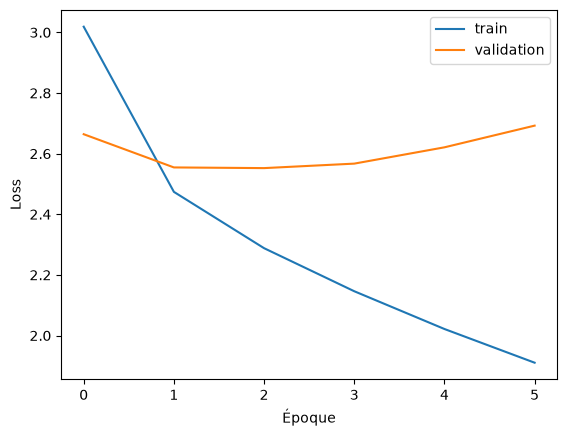

1927623

In [ ]:
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

Ici, la courbe permet de suivre l’évolution de la loss de notre modèle au fil des époques. On observe une loss relativement élevée et un *early stopping* après cinq epoch.
Nous avons comparé ce résultat à deux autres expériences réalisées de notre côté. Pour la première, nous avons utilisé ***6 000 verbose et 25 000*** images d’entraînement. la courbe obtenue est présentée ci-dessous :

![Courbe loss](src/loss25k.png)

Et un autre avec ***5000 verbose et 30000 images*** pour l'entrainement:

![Courbe loss](src/loss30.png)

La comparaison des trois courbes montre que la loss de l’architecture étudiée est nettement plus élevée que celles des deux autres expériences. Elle semble également indiquer un surapprentissage. La différence entre les deux autres courbes qu’on peut voir est assez faible, mais l’élément qui a le plus d’impact sur notre loss est le nombre d’images choisies pour l’entraînement. Donc on en déduit que plus il y'aura d'images pour le train, plus la loss sera faible.


### Affichage

Ici, nous testons le modèle sur une image du jeu de test. La fonction *generate_caption* extrait les features de l'image, puis génère la légende mot par mot à partir de "start", en tirant chaque mot au hasard selon les scores du décodeur, jusqu'à "end". Elle enregistre aussi les poids d'attention. Enfin, nous comparons la vraie légende à la légende prédite.

In [55]:
CKPT_DIR = Path("checkpoints_gru")
MAX_WORDS = 20

config = json.loads((CKPT_DIR / "config.json").read_text())
tokenizer = tokenizer_from_json((CKPT_DIR / "tokenizer.json").read_text(encoding="utf-8"))

IMAGE_SIZE = tuple(config["image_size"])
start_token_id = config["start_token_id"]
end_token_id = config["end_token_id"]


inception = InceptionV3(weights="imagenet", include_top=False, pooling=None,
                        input_shape=(*IMAGE_SIZE, 3))
inception.trainable = False
inputs = Input(shape=(*IMAGE_SIZE, 3))
image_encoder = Model(inputs, inception(inputs, training=False))


encoder = CNN_Encoder(config["embedding_dim"])
decoder = RNN_Decoder(config["embedding_dim"], config["rnn_units"], config["vocab_size"])


dummy = encoder(tf.zeros((1, 64, 2048)))
h0 = decoder.reset_state(1)
decoder(tf.constant([[start_token_id]]), dummy, h0)

tf.train.Checkpoint(encoder=encoder, decoder=decoder).read(
    str(CKPT_DIR / "best")
).expect_partial()

BLOCKED_IDS = [0, 1, start_token_id]


def generate_caption(image_path):
    image = tf.io.decode_jpeg(tf.io.read_file(str(image_path)), channels=3)
    image = preprocess_input(tf.image.resize(image, IMAGE_SIZE))
    image = tf.expand_dims(image, axis=0)

    features = tf.reshape(image_encoder(image, training=False), (1, 64, 2048))
    encoded = encoder(features)

    hidden = decoder.reset_state(1)
    word_id = tf.constant([[start_token_id]])

    words = []
    for _ in range(MAX_WORDS):
        logits, hidden, _ = decoder(word_id, encoded, hidden)
        scores = logits[0].numpy()
        scores[BLOCKED_IDS] = -1e9
        predicted_id = int(np.argmax(scores))
        if predicted_id == end_token_id:
            break
        words.append(tokenizer.index_word.get(predicted_id, ""))
        word_id = tf.constant([[predicted_id]])

    return " ".join(words)


def show_caption(image_path):
    caption = generate_caption(image_path)
    plt.imshow(plt.imread(str(image_path)))
    plt.axis("off")
    plt.title(caption, fontsize=10)
    plt.show()
    print("Légende :", caption)

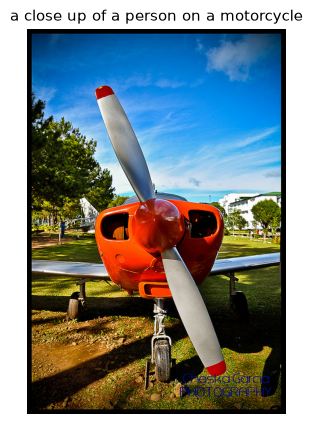

Générée : a close up of a person on a motorcycle
Références humaines :
  - A small red airplane is parked in a field.
  - The front propeller of an orange airplane standing in grass.
  - An airplane sitting still in some green grass.
  - a close up of the front of a small plane with a propellor
  - A small, parked propellor airplane seen from the front
------------------------------------------------------------


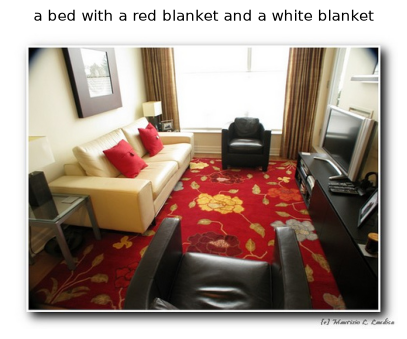

Générée : a bed with a red blanket and a white blanket
Références humaines :
  - A living room with three sofas and a unique carpet.
  - A living room with couches, chairs, end tables and a television.
  - A living room area with two chairs and a couch.
  - The living room has a couch, two easy chairs, and a television in it.
  - a living room filled with couch and chairs and a carpet
------------------------------------------------------------


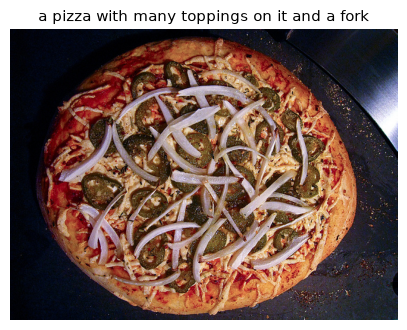

Générée : a pizza with many toppings on it and a fork
Références humaines :
  - A pizza topped with onions, peppers and cheese.
  - A freshly baked pizza with onions and hot peppers.
  - A pizza with cheese, onions and hot peppers.
  - A pizza sitting on top of a pizza pan near an oven.
  - A pizza with cheese peppers and onions on it.
------------------------------------------------------------


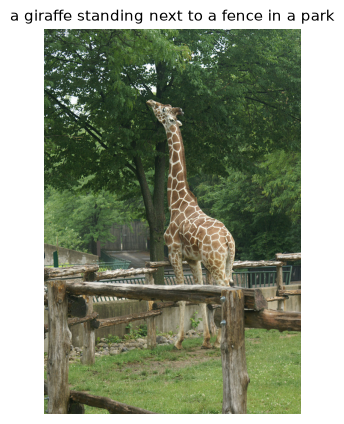

Générée : a giraffe standing next to a fence in a park
Références humaines :
  - a large giraffe that is standing up tall
  - A giraffe in an enclosure eating leaves from a tree.
  - A giraffe is standing under a tree outside
  - A giraffes reaching for a tree branch above him
  - A giraffe reaches for some leaves off of a tree.
------------------------------------------------------------


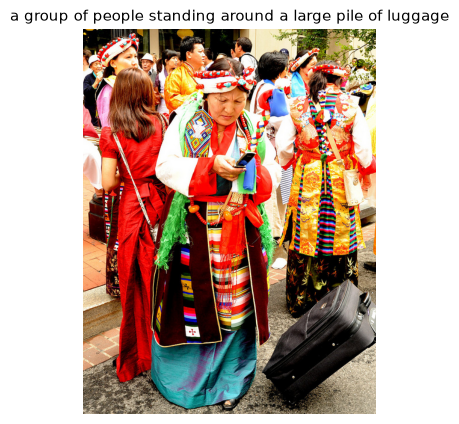

Générée : a group of people standing around a large pile of luggage
Références humaines :
  - A group of Tibet tourists with luggage and one is looking at her cell phone.
  - A group of people dresses in costume marching down a street.
  - A group of people in ethnic farm with luggage on a street.
  - A woman wears a traditional costume during a street fair
  - Crowd of people with several dressed in cultural traditional costumes.
------------------------------------------------------------


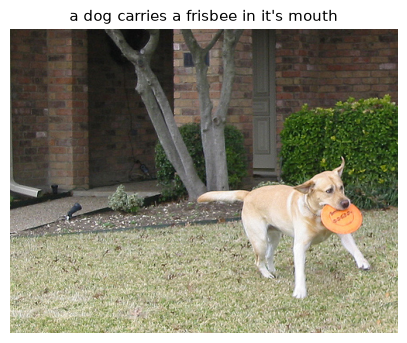

Générée : a dog carries a frisbee in it's mouth
Références humaines :
  - A brown dog with an orange frisbee in it's mouth.
  - A dog catching a Frisbee in the front yard.
  - A dog is in a yard with a Frisbee in its mouth.
  - The dog has a frisby in the mouth.
  - A dog biting a frisbee in front of a house
------------------------------------------------------------


In [56]:
all_val_ids = np.array(sorted(val_records))
rng = np.random.default_rng(1)
sample_ids = rng.choice(all_val_ids, size=6, replace=False)

for image_id in sample_ids:
    record = val_records[int(image_id)]
    generated = generate_caption(record["image_path"])

    plt.figure(figsize=(5, 5))
    plt.imshow(plt.imread(str(record["image_path"])))
    plt.axis("off")
    plt.title(generated, fontsize=11)
    plt.show()

    print("Générée :", generated)
    print("Références humaines :")
    for ref in record["captions"]:
        print("  -", ref.strip())
    print("-" * 60)

### Score Bleu

In [ ]:
N_BLEU_IMAGES = 2000      
BLEU_BATCH = 64
VAL_FEATURES_DIR = FEATURES_DIR / "validation"
smooth = SmoothingFunction().method1

BLEU_WEIGHTS = {
    "BLEU-1": (1.0, 0, 0, 0),
    "BLEU-2": (0.5, 0.5, 0, 0),
    "BLEU-3": (1/3, 1/3, 1/3, 0),
    "BLEU-4": (0.25, 0.25, 0.25, 0.25),
}

logit_mask = np.zeros(config["vocab_size"], dtype=np.float32)
logit_mask[BLOCKED_IDS] = -1e9
logit_mask = tf.constant(logit_mask)


def greedy_decode_batch(features):
    encoded = encoder(features)
    batch_size = tf.shape(features)[0]
    hidden = decoder.reset_state(batch_size)
    word_ids = tf.fill((batch_size, 1), start_token_id)

    predictions = []
    for _ in range(MAX_WORDS):
        logits, hidden, _ = decoder(word_ids, encoded, hidden)
        pred = tf.argmax(logits + logit_mask, axis=-1, output_type=tf.int32)
        predictions.append(pred)
        word_ids = tf.expand_dims(pred, 1)

    return tf.stack(predictions, axis=1).numpy()


def ids_to_words(seq):
    words = []
    for i in seq:
        if i == end_token_id:
            break
        word = tokenizer.index_word.get(int(i), "")
        if word:
            words.append(word)
    return words


def evaluate_bleu(records, n_images=N_BLEU_IMAGES, seed=SEED):
    available = sorted(
        int(p.stem) for p in VAL_FEATURES_DIR.glob("*.npy")
        if not p.name.endswith(".tmp.npy") and int(p.stem) in records
    )
    if n_images is not None:
        rng = np.random.default_rng(seed)
        available = rng.choice(available, size=min(n_images, len(available)), replace=False)

    references, hypotheses, image_ids = [], [], []
    start = time.time()

    for b in range(0, len(available), BLEU_BATCH):
        batch_ids = [int(i) for i in available[b:b + BLEU_BATCH]]
        feats = np.stack([
            np.load(VAL_FEATURES_DIR / f"{i}.npy").astype(np.float32)
            for i in batch_ids
        ])
        preds = greedy_decode_batch(tf.constant(feats))

        for image_id, seq in zip(batch_ids, preds):
            hypotheses.append(ids_to_words(seq))
            references.append([text_to_word_sequence(c) for c in records[image_id]["captions"]])
            image_ids.append(image_id)

    scores = {
        name: corpus_bleu(references, hypotheses, weights=w, smoothing_function=smooth)
        for name, w in BLEU_WEIGHTS.items()
    }

    print(f"BLEU calculé sur {len(hypotheses):,} images en {time.time() - start:.0f}s")
    for name, value in scores.items():
        print(f"  {name} : {value:.4f}")

    return scores, references, hypotheses, image_ids


bleu_scores, bleu_refs, bleu_hyps, bleu_ids = evaluate_bleu(val_records)


BLEU calculé sur 2,000 images en 25s
  BLEU-1 : 0.6591
  BLEU-2 : 0.4797
  BLEU-3 : 0.3384
  BLEU-4 : 0.2369


Le score *Bleu* est utilisé pour mesuré de la légende généré par notre modèle comparait au vrai légéndes fournit par le dataset *Coco*, mes valeurs sont comprise entre 0 et 1, plus il est proche de 1, mieux cela est.
Ici chaque score Bleu (*1,2,3,4*) ont chacun leur role, le score **Bleu 1** va lui regarder si les mots sont les mêmes de la légende d'origine, celle ci sert pour montrer si notre modèle arrive à detecter les éléments de la photo. Pour le score **Bleu 2**, lui va etre sur les suites de 2 mots, il regarde si bien cette suite de mots ce trouve dans la légende. Pour le score **Bleu 3** est assez similaire à Bleu 2, mais va regarder une suite de 3 mots. Et pour le score **Bleu 4** qui est le plus courant utilisé, il regarde une suite de groupes de 4 mots. 

Il est donc plutôt normal de voir notre score diminué petit à petit en passant d'un Blue à l'autre, mais que veut dire nos résultats ?
- Le score Bleu 1 montre que notre modèle 2 mots sur 3, donc détecte assez bien le contexte de la photo.
- Le score Bleu 2, lui montre qu'une fois sur 2 quasiement le modèle arrive à faire de bon groupement de mots.
- Le score Bleu 3, montre une syntaxe assez solide avec une fois sur 3, trois mots a la suite qui sont bien dans la légende.
- Le score Bleu 4, même si assez faible montre que une fois sur 4, notre modèle détecte bien et parle assez proche du language humain.

Même si le score de Bleu 4 est assez faible, il est proche des scores obtenues en général avec cette architecture ce qui est très positif pour notre modèle qui démontre qu'il détecte assez bien le contexte général de l'image le plus souvent.

### Score CIDER


In [ ]:
def evaluate_cider(references, hypotheses, image_ids):
    gts = {i: [" ".join(ref) for ref in refs] for i, refs in zip(image_ids, references)}
    res = {i: [" ".join(hyp)] for i, hyp in zip(image_ids, hypotheses)}

    cider_score, per_image_scores = Cider().compute_score(gts, res)

    print(f"CIDEr-D sur {len(res):,} images : {cider_score:.4f}")
    return cider_score, np.asarray(per_image_scores)


cider_score, cider_per_image = evaluate_cider(bleu_refs, bleu_hyps, bleu_ids)


CIDEr-D sur 2,000 images : 0.7727


Nous utilisons en complément le score CIDER qui lui aussi évalue le légendage d'image. Mais comparait au score Bleu, CIDER lui va regarder à quel point la légende généré est proche de ce que la légende réelle a dit et ce que l'Humain écricraient.
Ce score permet d'etre moins rigide sur l'exactitude de la légénde originalle mais plutot de priorisé si le modèle saisit bien le sens de l'image et que la légende soit proche d'une reponse qui serait Humaine.

Avec notre score de ***0.7727***, nous avons un model assez performant pour le nombre d'image utilisé pour l'entrainement, celui ci peut etre encore amélioré mais les légendes généré par ce dernier sont assez proche d'une réponse humaine. Ce qui est très bénéfique car cela valide que notre modèle saisit correctement les informations de l'image et ne les redrisbuent pas de facon aléatoire mais de façon logique et compréhensible.



## Pourquoi cette architecture ?
Nous avons choisi cette architecture plutôt que d’autres testées, comme celles dont les courbes démontraient de meilleures loss. Cependant, lorsque nous calculions le score BLEU, nos modèles dégringolaient en termes d’accuracy :

![Score bleu](src/score.png)

Comme vous pouvez le voir, sur l’autre architecture testée, le résultat du score BLEU est catastrophique, avec des résultats très bas. Nous avons donc fait le choix de partir sur cette architecture en priorisant le résultat du captioning plutôt que la loss obtenue par cette architecture, grâce aux scores BLEU et CIDEr, qui sont extrêmement intéressants et de qualité pour le nombre de données choisi et testé.

## Piste d'amélioration

Dans notre modèle, nous avons vu que l’impact principal était, en premier lieu, la quantité d’images sélectionnées pour l’entraînement : plus il y a d’images, plus la loss est basse et *l’accuracy du captioning* est bonne. Nous avons actuellement une val loss assez élevée, et le but principal sera donc de la faire diminuer en augmentant le nombre d’images, tout en perfectionnant notre modèle pour qu’il ne surapprenne pas. Si, plus tard, nous ajoutons des légendes plus longues et davantage de données, nous pouvons aussi basculer vers le *LSTM*.

Donc, pour la continuité de notre modèle, les principaux aspects seront :
- Augmenté le nombre de jeu de donnés pour l'entrainement.
- Améliorer la val loss sur cette arechitecture tout en gardant un score Bleu et CIDER élevé.
- Si ajout de légende plus longue, tester de nouveau le LSTM.


## Workflow :

Nous avons ensuite créé un notebook combinant nos 3 livrables, permettant le traitement de l'image, le débruitage et le captioning de n'importe quelle image. Vous pouvez y accéder en cliquant sur ce lien : [lien](workflow.ipynb)